# Exploración aislada de ecommerce_orders.parquet

## 1. Objetivo y granularidad

Exploro únicamente `datos/ecommerce_orders.parquet`; no consulto ni cruzo otros archivos de datos. Busco entender estructura, granularidad, calidad, cobertura y riesgos para métricas online. Cuento filas como registros de origen: un `order_id` único no confirma que represente un pedido completo, una línea o una versión. No calculo ingresos netos, margen ni conversión monetaria sin reglas confirmadas.

Conservo los originales en memoria y omito valores de clientes en todas las salidas. Mi interpretación comercial y los supuestos permanecen pendientes de revisión; la ejecución técnica corresponde a la IA.

In [1]:
# Identifico la raíz y la versión del único archivo de datos que voy a leer.
from pathlib import Path
import hashlib
import html
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display, HTML, Markdown, SVG

raiz = Path.cwd() if (Path.cwd() / 'datos').is_dir() else Path.cwd().parent
fuente = raiz / 'datos/ecommerce_orders.parquet'
huella_inicial = hashlib.sha256(fuente.read_bytes()).hexdigest()
tabla_parquet = pq.read_table(fuente)
original = tabla_parquet.to_pandas()
tablas = {}
leyendas = {}
def mostrar(nombre, tabla, leyenda):
    tablas[nombre] = tabla.copy()
    leyendas[nombre] = leyenda
    display(Markdown('**Leyenda:** ' + leyenda + ' El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.'))
    display(HTML(tabla.to_html(index=False, escape=True, float_format=lambda x: f'{x:,.4f}')))

version = pd.DataFrame([
    ('Archivo', 'datos/ecommerce_orders.parquet'), ('Tamaño en bytes', fuente.stat().st_size),
    ('SHA-256', huella_inicial), ('Registros', len(original)), ('Columnas originales', len(original.columns))
], columns=['Identificación', 'Resultado'])
mostrar('version', version, 'Identifico la extracción analizada; tamaño en bytes y conteos enteros. La huella no acredita completitud de origen.')

**Leyenda:** Identifico la extracción analizada; tamaño en bytes y conteos enteros. La huella no acredita completitud de origen. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Identificación,Resultado
Archivo,datos/ecommerce_orders.parquet
Tamaño en bytes,724121
SHA-256,00c560b39425fe7f0088fbe20c66c2b8861d10c2c7006ba6e7335cdd6dfc856e
Registros,9947
Columnas originales,11


## 2. Esquema y diccionario

Interpreto los nombres como indicios, sin sustituir el diccionario del sistema. Los cinco campos personales o de envío se describen únicamente por nombre, tipo y calidad agregada; no muestro ejemplos ni agrupo por cliente o dirección. `shipping_city` tampoco identifica al almacén que surte la operación.

In [2]:
# Describo campos y ausencia sin mostrar ningún valor personal de la fuente.
significados = {
    'order_id': 'Identificador de origen; pedido, línea y estabilidad pendientes (Q31).',
    'fecha': 'Texto temporal; evento y zona pendientes (Q34).',
    'product_handle': 'Clave textual de producto; variante y estabilidad pendientes (Q32).',
    'cantidad': 'Cantidad registrada; unidad física pendiente (Q16).',
    'amount': 'Importe original en currency; total de línea y componentes pendientes (Q33).',
    'currency': 'Código de moneda del importe; no sumo monedas distintas.',
    'customer_name': 'Nombre personal; excluyo valores de las salidas.',
    'customer_email': 'Correo personal; excluyo valores de las salidas.',
    'customer_rfc': 'Dato fiscal personal; nulo no implica pedido inválido (Q44).',
    'shipping_city': 'Ciudad de envío; no acredita tienda de cumplimiento (Q35).',
    'shipping_address': 'Dirección personal; excluyo valores de las salidas.'
}
esquema = pd.DataFrame([{'Campo': f.name, 'Tipo Parquet': str(f.type),
    'Tipo pandas': str(original[f.name].dtype), 'Nulos': int(original[f.name].isna().sum()),
    'Interpretación y límite': significados[f.name]} for f in tabla_parquet.schema])
mostrar('esquema', esquema, 'Diccionario de todas las columnas originales. Nulos son valores ausentes reconocidos por pandas, no textos vacíos.')
textos = original.select_dtypes(include=['object', 'string'])
calidad_texto = pd.DataFrame([{'Campo': c,
    'Textos vacíos o espacios': int(textos[c].str.fullmatch(r'\s*', na=False).sum()),
    'Textos con espacios en extremos': int((textos[c].notna() & textos[c].ne(textos[c].str.strip())).sum())
} for c in textos])
mostrar('calidad_texto', calidad_texto, 'Controles agregados en campos textuales; conteo de filas por campo, sin ejemplos personales. Los nulos se cuentan por separado en el esquema.')

**Leyenda:** Diccionario de todas las columnas originales. Nulos son valores ausentes reconocidos por pandas, no textos vacíos. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Campo,Tipo Parquet,Tipo pandas,Nulos,Interpretación y límite
order_id,large_string,object,0,"Identificador de origen; pedido, línea y estabilidad pendientes (Q31)."
fecha,large_string,object,0,Texto temporal; evento y zona pendientes (Q34).
product_handle,large_string,object,0,Clave textual de producto; variante y estabilidad pendientes (Q32).
cantidad,int64,int64,0,Cantidad registrada; unidad física pendiente (Q16).
amount,double,float64,0,Importe original en currency; total de línea y componentes pendientes (Q33).
currency,large_string,object,0,Código de moneda del importe; no sumo monedas distintas.
customer_name,large_string,object,0,Nombre personal; excluyo valores de las salidas.
customer_email,large_string,object,0,Correo personal; excluyo valores de las salidas.
customer_rfc,large_string,object,8462,Dato fiscal personal; nulo no implica pedido inválido (Q44).
shipping_city,large_string,object,0,Ciudad de envío; no acredita tienda de cumplimiento (Q35).


**Leyenda:** Controles agregados en campos textuales; conteo de filas por campo, sin ejemplos personales. Los nulos se cuentan por separado en el esquema. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Campo,Textos vacíos o espacios,Textos con espacios en extremos
order_id,0,0
fecha,0,0
product_handle,0,0
currency,0,0
customer_name,0,0
customer_email,0,0
customer_rfc,0,0
shipping_city,0,0
shipping_address,0,0


## 3. Columnas derivadas y controles de calidad

Creo `datos` como copia; mantengo sin cambios las columnas originales. Introduzco estas derivadas antes de usarlas:

- `fecha_dt`: desde `fecha`, con formato exacto `YYYY-MM-DD HH:MM:SS`; un valor no interpretable se vuelve `NaT`. Sirve para cobertura; no asigno zona ni invento evento contable.
- `dia`: fecha normalizada a medianoche desde `fecha_dt`; conserva `NaT`. Agrupo días de la marca original, sin convertir zonas.
- `mes`: período mensual desde `fecha_dt`, conservando `NaT`. Sirve para evolución por moneda.
- `cantidad_num` y `amount_num`: copias numéricas de sus campos originales; una conversión imposible produce `NaN`. Valido finitud aparte, porque convertir no acredita validez comercial.
- `importe_unitario`: `amount_num / cantidad_num` únicamente con ambos valores finitos y cantidad positiva; los demás casos quedan `NaN`. Es importe por unidad registrada en moneda original, condicionado a que `amount` sea total de línea; no es precio de lista.

Los patrones de identificadores son controles de la forma observada, no contratos confirmados. Distingo nulo, cero y ausencia de fila; no relleno ninguno automáticamente.

In [3]:
# Separo las conversiones y controlo duplicados, dominio y signos sin corregir el origen.
datos = original.copy(deep=True)
datos['fecha_dt'] = pd.to_datetime(datos['fecha'], format='%Y-%m-%d %H:%M:%S', errors='coerce', exact=True)
datos['dia'] = datos['fecha_dt'].dt.normalize()
datos['mes'] = datos['fecha_dt'].dt.to_period('M')
for campo in ['cantidad', 'amount']:
    datos[campo + '_num'] = pd.to_numeric(datos[campo], errors='coerce')
elegibles = np.isfinite(datos['cantidad_num']) & datos['cantidad_num'].gt(0) & np.isfinite(datos['amount_num'])
datos['importe_unitario'] = (datos['amount_num'] / datos['cantidad_num']).where(elegibles)
controles = [('Duplicados exactos adicionales', int(original.duplicated().sum())),
    ('Repeticiones adicionales de order_id', int(original['order_id'].duplicated().sum())),
    ('order_id nulos', int(original['order_id'].isna().sum())),
    ('order_id fuera de SHOP y siete dígitos', int((~original['order_id'].str.fullmatch(r'SHOP-\d{7}', na=False)).sum())),
    ('Fechas sin interpretar', int(datos['fecha_dt'].isna().sum())),
    ('Fechas fuera del patrón textual esperado', int((~original['fecha'].str.fullmatch(r'\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}', na=False)).sum())),
    ('Monedas fuera de MXN, USD y EUR', int((~datos['currency'].isin(['MXN','USD','EUR'])).sum())),
    ('Handles nulos', int(datos['product_handle'].isna().sum()))]
for c in ['cantidad_num', 'amount_num']:
    s = datos[c]
    controles.extend([(c + ': nulos o no convertibles', int(s.isna().sum())),
        (c + ': infinitos', int((s.notna() & ~np.isfinite(s)).sum())),
        (c + ': ceros', int(s.eq(0).sum())), (c + ': negativos', int(s.lt(0).sum()))])
controles.append(('Cantidades finitas no enteras', int((np.isfinite(datos['cantidad_num']) & datos['cantidad_num'].mod(1).ne(0)).sum())))
mostrar('calidad', pd.DataFrame(controles, columns=['Control', 'Registros']), 'Controles sobre todas las filas; duplicados adicionales excluyen la primera aparición. Cero alertas no demuestra exactitud comercial.')
coincidencias = datos.groupby(['fecha','product_handle','cantidad','amount','currency'], dropna=False).size()
granularidad = pd.DataFrame([
    ('order_id distintos no nulos', datos['order_id'].nunique()),
    ('Handles distintos no nulos', datos['product_handle'].nunique()),
    ('Grupos con igual fecha, handle, cantidad, amount y currency', int(coincidencias.gt(1).sum())),
    ('Filas en esos grupos', int(coincidencias[coincidencias.gt(1)].sum()))
], columns=['Medida', 'Resultado'])
mostrar('granularidad', granularidad, 'Cuento identidades y coincidencias comerciales exactas de cinco campos no personales; no muestro filas individuales ni considero estas coincidencias duplicados confirmados.')

**Leyenda:** Controles sobre todas las filas; duplicados adicionales excluyen la primera aparición. Cero alertas no demuestra exactitud comercial. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Control,Registros
Duplicados exactos adicionales,0
Repeticiones adicionales de order_id,0
order_id nulos,0
order_id fuera de SHOP y siete dígitos,0
Fechas sin interpretar,0
Fechas fuera del patrón textual esperado,0
"Monedas fuera de MXN, USD y EUR",0
Handles nulos,0
cantidad_num: nulos o no convertibles,0
cantidad_num: infinitos,0


**Leyenda:** Cuento identidades y coincidencias comerciales exactas de cinco campos no personales; no muestro filas individuales ni considero estas coincidencias duplicados confirmados. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Medida,Resultado
order_id distintos no nulos,9947
Handles distintos no nulos,33
"Grupos con igual fecha, handle, cantidad, amount y currency",2
Filas en esos grupos,4


**Interpretación:** la unicidad describe esta extracción; no prueba estabilidad entre cargas ni permite contar pedidos completos. Las coincidencias sin identificador ni datos personales pueden ser operaciones independientes. No las elimino ni reconstruyo tickets por hora (Q09/Q31; D012).

## 4. Cobertura temporal

Uso un calendario diario inclusivo entre mínimo y máximo interpretados. Una fecha sin filas es ausencia de actividad observada; no demuestra venta cero ni fallo de extracción. La cobertura global puede ocultar huecos de una moneda o producto. No interpreto la primera y última marca como horario de apertura ni corte íntegro.

In [4]:
# Mido presencia diaria global y por moneda sin imputar actividad a los días ausentes.
inicio, fin = datos['dia'].min(), datos['dia'].max()
calendario = pd.date_range(inicio, fin, freq='D')
cobertura = pd.DataFrame([
    ('Primera marca interpretada', str(datos['fecha_dt'].min())),
    ('Última marca interpretada', str(datos['fecha_dt'].max())),
    ('Días calendario inclusivos', len(calendario)),
    ('Días con registros', datos['dia'].nunique()),
    ('Días sin registros', len(calendario.difference(datos['dia'].dropna().unique()))),
    ('Meses con registros', datos['mes'].nunique()),
    ('Marcas con segundos distintos de cero', int(datos['fecha_dt'].dt.second.ne(0).sum()))
], columns=['Medida', 'Resultado'])
mostrar('cobertura', cobertura, 'Ventana completa del archivo, fechas sin zona confirmada; conteos de días y meses, sin extrapolar fuera de los extremos.')
cobertura_moneda = []
for moneda, g in datos.groupby('currency', dropna=False):
    cobertura_moneda.append({'Moneda': moneda, 'Primera fecha': str(g['dia'].min().date()),
        'Última fecha': str(g['dia'].max().date()), 'Días con registros': g['dia'].nunique(),
        'Días sin registros en ventana global': len(calendario.difference(g['dia'].dropna().unique()))})
mostrar('cobertura_moneda', pd.DataFrame(cobertura_moneda), 'Presencia de cada moneda contra el mismo calendario global inclusivo; un hueco no se transforma en importe cero ni prueba extracción incompleta.')
cobertura_handle = datos.groupby('product_handle', dropna=False).agg(
    Registros=('order_id','size'), Días_con_registros=('dia','nunique'), Meses_con_registros=('mes','nunique'))
mostrar('cobertura_handle', cobertura_handle.reset_index().rename(columns={'product_handle':'Handle', 'Días_con_registros':'Días con registros', 'Meses_con_registros':'Meses con registros'}),
    'Todos los handles, orden alfabético; filas, días y meses distintos con presencia en la ventana global. No presupongo surtido activo todos los días.')

**Leyenda:** Ventana completa del archivo, fechas sin zona confirmada; conteos de días y meses, sin extrapolar fuera de los extremos. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Medida,Resultado
Primera marca interpretada,2025-04-01 03:12:00
Última marca interpretada,2026-03-31 22:31:00
Días calendario inclusivos,365
Días con registros,365
Días sin registros,0
Meses con registros,12
Marcas con segundos distintos de cero,0


**Leyenda:** Presencia de cada moneda contra el mismo calendario global inclusivo; un hueco no se transforma en importe cero ni prueba extracción incompleta. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Primera fecha,Última fecha,Días con registros,Días sin registros en ventana global
EUR,2025-04-01,2026-03-31,261,104
MXN,2025-04-01,2026-03-31,365,0
USD,2025-04-01,2026-03-31,364,1


**Leyenda:** Todos los handles, orden alfabético; filas, días y meses distintos con presencia en la ventana global. No presupongo surtido activo todos los días. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Handle,Registros,Días con registros,Meses con registros
americano-cafe-grano-032,279,192,12
americano-cafe-molido-024,314,208,12
americano-cafe-molido-052,332,218,12
descafeinado-cafe-grano-010,309,206,12
descafeinado-cafe-grano-014,301,197,12
especial-cafe-grano-045,294,201,12
espresso-cafe-molido-054,342,212,12
estándar-cafe-grano-006,303,202,12
estándar-cafe-grano-069,309,211,12
estándar-cafe-molido-034,291,201,12


## 5. Cantidades, importes y moneda

Separo las estadísticas de importes por moneda. Las unidades son cantidades registradas sin unidad física confirmada; no las interpreto como piezas equivalentes entre productos. Las sumas son controles aritméticos del origen, no ingresos netos ni ventas pagadas. `double` introduce representación binaria: mostrar decimales no define exactitud ni política de redondeo.

In [5]:
# Describo magnitudes y conservo importes separados por moneda en todas las agregaciones.
resumen_moneda = datos.groupby('currency', dropna=False).agg(Registros=('order_id','size'),
    Cantidad_registrada=('cantidad_num',lambda s: s.sum(min_count=1)),
    Importe_original=('amount_num',lambda s: s.sum(min_count=1)), Handles=('product_handle','nunique')).reset_index()
resumen_moneda = resumen_moneda.rename(columns={'currency':'Moneda','Cantidad_registrada':'Cantidad registrada','Importe_original':'Importe original'})
resumen_moneda['Participación de registros %'] = resumen_moneda['Registros'] / len(datos) * 100
mostrar('monedas', resumen_moneda, 'Todas las filas por moneda; importe en unidades de la moneda indicada, participación sobre filas totales. No sumo la columna de importes entre monedas.')
etiquetas = {'count':'Observaciones','mean':'Media','std':'Desviación estándar muestral','min':'Mínimo','1%':'Percentil 1','25%':'Cuartil 1','50%':'Mediana','75%':'Cuartil 3','99%':'Percentil 99','max':'Máximo'}
distribucion_cantidad = datos['cantidad_num'].describe(percentiles=[.01,.25,.5,.75,.99]).rename(index=etiquetas).rename_axis('Estadística').reset_index(name='Cantidad registrada')
mostrar('cantidad', distribucion_cantidad, 'Distribución de cantidad por registro en toda la extracción; cuantiles con interpolación lineal de pandas, desviación con ddof=1. La suma de cantidades no acredita unidad física comparable.')
estadisticas = []
for moneda, g in datos.groupby('currency'):
    for campo, etiqueta in [('amount_num','Importe por registro'),('importe_unitario','Importe por unidad registrada')]:
        for estadistica, valor in g[campo].describe(percentiles=[.01,.25,.5,.75,.99]).items():
            estadisticas.append({'Moneda':moneda,'Medida':etiqueta,'Estadística':etiquetas[estadistica],'Valor':valor})
mostrar('importes', pd.DataFrame(estadisticas), 'Distribución por moneda, sin conversión. Valores en moneda original salvo Observaciones (conteo); importe unitario solo en filas elegibles, sin inferir precio de lista.')

**Leyenda:** Todas las filas por moneda; importe en unidades de la moneda indicada, participación sobre filas totales. No sumo la columna de importes entre monedas. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Registros,Cantidad registrada,Importe original,Handles,Participación de registros %
EUR,470,613,"9,885.8600",33,4.7250
MXN,6942,9231,"2,912,430.7400",33,69.7899
USD,2535,3448,"61,796.4600",33,25.4851


**Leyenda:** Distribución de cantidad por registro en toda la extracción; cuantiles con interpolación lineal de pandas, desviación con ddof=1. La suma de cantidades no acredita unidad física comparable. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Estadística,Cantidad registrada
Observaciones,"9,947.0000"
Media,1.3363
Desviación estándar muestral,0.8843
Mínimo,1.0000
Percentil 1,1.0000
Cuartil 1,1.0000
Mediana,1.0000
Cuartil 3,1.0000
Percentil 99,5.0000
Máximo,15.0000


**Leyenda:** Distribución por moneda, sin conversión. Valores en moneda original salvo Observaciones (conteo); importe unitario solo en filas elegibles, sin inferir precio de lista. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Medida,Estadística,Valor
EUR,Importe por registro,Observaciones,470.0000
EUR,Importe por registro,Media,21.0337
EUR,Importe por registro,Desviación estándar muestral,19.8783
EUR,Importe por registro,Mínimo,3.8500
EUR,Importe por registro,Percentil 1,4.0583
EUR,Importe por registro,Cuartil 1,9.9525
EUR,Importe por registro,Mediana,16.7600
EUR,Importe por registro,Cuartil 3,27.5975
EUR,Importe por registro,Percentil 99,84.1845
EUR,Importe por registro,Máximo,251.9300


## 6. Evolución mensual y concentración

Agrupo por mes y moneda sin seleccionar estatus porque no existe. No aplico descuentos, devoluciones ni conversiones supuestas. La ventana no contiene el mes anterior al primero observado; por ello no invento una base de crecimiento. El diagnóstico mensual no demuestra estacionalidad ni ingresos reconocidos (Q09/Q33/Q34/Q41).

In [6]:
# Agrego meses y productos por moneda y selecciono rankings con desempate reproducible.
mensual = datos.groupby(['mes','currency'], dropna=False).agg(Registros=('order_id','size'),
    Cantidad=('cantidad_num',lambda s:s.sum(min_count=1)), Importe=('amount_num',lambda s:s.sum(min_count=1)),
    Handles=('product_handle','nunique')).reset_index()
mensual = mensual.rename(columns={'mes':'Mes','currency':'Moneda','Cantidad':'Cantidad registrada','Importe':'Importe original'})
mostrar('mensual', mensual, 'Todos los meses y monedas con filas; importe en moneda original y cantidades registradas. No relleno combinaciones ausentes. Handles cuenta claves distintas por mes y moneda.')
por_producto = datos.groupby(['currency','product_handle'], dropna=False).agg(Registros=('order_id','size'),
    Cantidad=('cantidad_num',lambda s:s.sum(min_count=1)), Importe=('amount_num',lambda s:s.sum(min_count=1))).reset_index()
por_producto['Participación importe %'] = por_producto['Importe'] / por_producto.groupby('currency')['Importe'].transform('sum') * 100
ranking = por_producto.sort_values(['currency','Importe','product_handle'], ascending=[True,False,True]).groupby('currency', group_keys=False).head(10)
mostrar('ranking', ranking.rename(columns={'currency':'Moneda','product_handle':'Handle','Cantidad':'Cantidad registrada','Importe':'Importe original'}),
    'Diez handles con mayor importe por moneda durante toda la ventana; desempato por handle alfabético y mantengo diez posiciones. Participación sobre importe total de su moneda; no mide margen ni rotación.')

**Leyenda:** Todos los meses y monedas con filas; importe en moneda original y cantidades registradas. No relleno combinaciones ausentes. Handles cuenta claves distintas por mes y moneda. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Mes,Moneda,Registros,Cantidad registrada,Importe original,Handles
2025-04,EUR,43,62,"1,104.1800",23
2025-04,MXN,618,827,"267,327.7200",33
2025-04,USD,215,294,"5,255.4700",33
2025-05,EUR,36,47,729.0100,24
2025-05,MXN,592,779,"255,221.9100",33
2025-05,USD,201,303,"5,383.2800",33
2025-06,EUR,35,43,526.3500,19
2025-06,MXN,531,746,"240,541.5600",33
2025-06,USD,200,287,"4,956.3900",33
2025-07,EUR,39,56,950.7600,22


**Leyenda:** Diez handles con mayor importe por moneda durante toda la ventana; desempato por handle alfabético y mantengo diez posiciones. Participación sobre importe total de su moneda; no mide margen ni rotación. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Handle,Registros,Cantidad registrada,Importe original,Participación importe %
EUR,taza-mercancia-039,23,31,"1,279.6300",12.9440
EUR,termo-mercancia-055,15,22,708.9000,7.1708
EUR,prensa-francesa-mercancia-004,13,16,568.7800,5.7535
EUR,termo-mercancia-031,15,18,507.1200,5.1298
EUR,termo-mercancia-046,14,18,492.0300,4.9771
EUR,filtros-mercancia-047,15,19,485.3000,4.9090
EUR,descafeinado-cafe-grano-014,22,26,460.7900,4.6611
EUR,molinillo-mercancia-070,18,23,441.6200,4.4672
EUR,termo-mercancia-029,12,13,420.2400,4.2509
EUR,descafeinado-cafe-grano-010,13,20,368.7400,3.7300


**Leyenda:** Muestro todos los meses observados por moneda, con importe en su moneda original y ejes verticales independientes desde cero. No comparo alturas entre paneles ni interpreto la línea como ingresos netos. Las cifras exactas están en la tabla mensual.

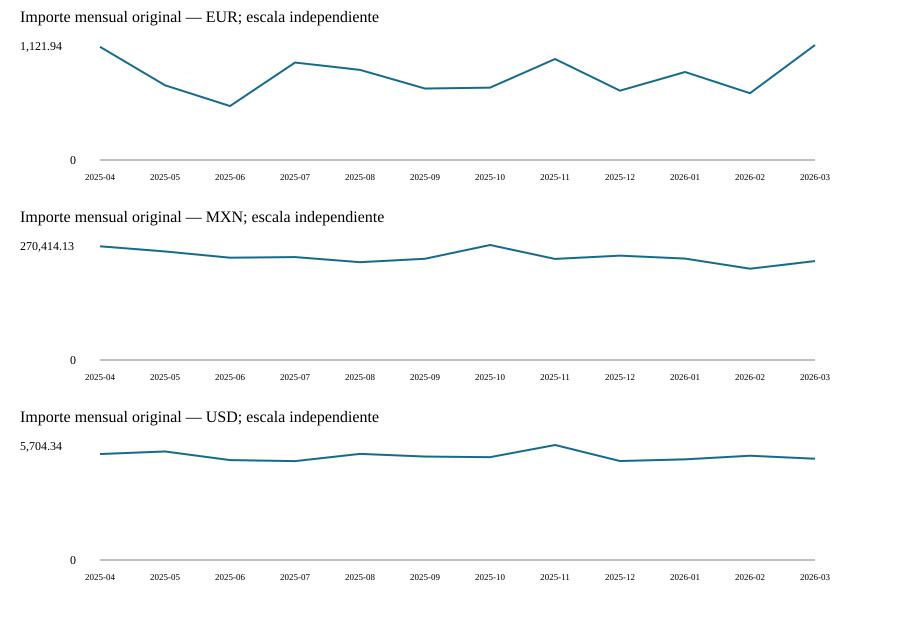

In [7]:
# Visualizo series independientes con escalas propias para evitar comparar monedas como equivalentes.
partes = ['<svg xmlns="http://www.w3.org/2000/svg" width="900" height="620" viewBox="0 0 900 620"><rect width="900" height="620" fill="white"/>']
for panel, (moneda, g) in enumerate(mensual.groupby('Moneda')):
    g = g.sort_values('Mes')
    base = panel * 200
    maximo = g['Importe original'].max()
    puntos = ' '.join(f'{100+i*65},{base+160-v/maximo*115:.2f}' for i,v in enumerate(g['Importe original']))
    partes.append(f'<text x="20" y="{base+22}" font-size="16">Importe mensual original — {html.escape(moneda)}; escala independiente</text>')
    partes.append(f'<text x="20" y="{base+50}" font-size="12">{maximo:,.2f}</text><text x="70" y="{base+164}" font-size="12">0</text>')
    partes.append(f'<line x1="100" x2="815" y1="{base+160}" y2="{base+160}" stroke="gray"/><polyline points="{puntos}" fill="none" stroke="#146b8c" stroke-width="2"/>')
    for i, mes in enumerate(g['Mes']):
        partes.append(f'<text x="{100+i*65}" y="{base+180}" font-size="9" text-anchor="middle">{mes}</text>')
partes.append('</svg>')
display(Markdown('**Leyenda:** Muestro todos los meses observados por moneda, con importe en su moneda original y ejes verticales independientes desde cero. No comparo alturas entre paneles ni interpreto la línea como ingresos netos. Las cifras exactas están en la tabla mensual.'))
display(SVG(''.join(partes)))

## 7. Señales estadísticas dentro de producto y moneda

Para evitar comparar precios de productos o monedas diferentes, evalúo `importe_unitario` por `product_handle` y `currency`. Creo `q1`, `q3`, `iqr`, `limite_inferior` y `limite_superior` como resumen de esos grupos; son cuartiles y cercas en moneda por unidad registrada. Uso interpolación lineal y `IQR = Q3 − Q1`; exijo al menos cuatro observaciones y dispersión positiva. Uno ese resumen a una copia de los campos analíticos, sin datos personales.

`evaluable` indica que el grupo cumple esos requisitos y la razón es finita; `senal_iqr` indica que rebasa estrictamente `Q1 − 1.5×IQR` o `Q3 + 1.5×IQR`. Un caso sin evaluación no equivale a normalidad: mantengo su conteo aparte. Son señales para revisar, no errores confirmados ni candidatos automáticos a eliminación.

In [8]:
# Busco extremos comparables dentro de cada handle y moneda sin descartar observaciones.
base_iqr = datos[['product_handle','currency','importe_unitario']].copy()
grupos_iqr = base_iqr.groupby(['product_handle','currency'])['importe_unitario'].agg(
    observaciones='count', q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75)).reset_index()
grupos_iqr['iqr'] = grupos_iqr['q3'] - grupos_iqr['q1']
grupos_iqr['limite_inferior'] = grupos_iqr['q1'] - 1.5 * grupos_iqr['iqr']
grupos_iqr['limite_superior'] = grupos_iqr['q3'] + 1.5 * grupos_iqr['iqr']
revision = base_iqr.merge(grupos_iqr, on=['product_handle','currency'], how='left', validate='many_to_one')
revision['evaluable'] = revision['observaciones'].ge(4) & revision['iqr'].gt(0) & np.isfinite(revision['importe_unitario'])
revision['senal_iqr'] = revision['evaluable'] & (revision['importe_unitario'].lt(revision['limite_inferior']) | revision['importe_unitario'].gt(revision['limite_superior']))
resumen_iqr = revision.groupby('currency').agg(Registros=('evaluable','size'), Evaluados=('evaluable','sum'), Señalados=('senal_iqr','sum')).reset_index().rename(columns={'currency':'Moneda'})
resumen_iqr['Sin evaluación'] = resumen_iqr['Registros'] - resumen_iqr['Evaluados']
mostrar('iqr', resumen_iqr, 'Conteos por moneda de toda la extracción. Señalados es subconjunto de Evaluados; Sin evaluación conserva filas no elegibles. Cercas estrictas por handle y moneda, sin eliminar casos.')
grupos_iqr['Evaluable'] = grupos_iqr['observaciones'].ge(4) & grupos_iqr['iqr'].gt(0)
mostrar('cercas_iqr', grupos_iqr.rename(columns={'product_handle':'Handle','currency':'Moneda','observaciones':'Observaciones','q1':'Cuartil 1','q3':'Cuartil 3','iqr':'IQR','limite_inferior':'Cerca inferior','limite_superior':'Cerca superior'}),
    'Todos los grupos handle y moneda, en orden alfabético; cuartiles, IQR y cercas en moneda por unidad registrada. Una cerca negativa no significa importe negativo observado; Evaluable indica tamaño y dispersión suficientes.')
dispersion = grupos_iqr.groupby('currency').agg(Grupos=('observaciones','size'), Grupos_con_IQR_cero=('iqr',lambda s:s.eq(0).sum())).reset_index()
mostrar('dispersion', dispersion.rename(columns={'currency':'Moneda','Grupos_con_IQR_cero':'Grupos con IQR cero'}), 'Todos los grupos producto y moneda; IQR cero impide evaluar esta regla y no demuestra ausencia de extremos.')
detalle_senales = revision.loc[revision['senal_iqr']].groupby(['currency','product_handle']).agg(
    Filas_señaladas=('importe_unitario','size'), Mínimo_señalado=('importe_unitario','min'), Máximo_señalado=('importe_unitario','max'),
    Cerca_inferior=('limite_inferior','first'), Cerca_superior=('limite_superior','first')).reset_index()
mostrar('detalle_senales', detalle_senales.rename(columns={'currency':'Moneda','product_handle':'Handle','Filas_señaladas':'Filas señaladas','Mínimo_señalado':'Mínimo señalado','Máximo_señalado':'Máximo señalado','Cerca_inferior':'Cerca inferior','Cerca_superior':'Cerca superior'}), 'Todos los grupos con señales, sin filas individuales ni identificadores personales; razones y cercas en moneda original por unidad registrada. Orden alfabético por moneda y handle.')


**Leyenda:** Conteos por moneda de toda la extracción. Señalados es subconjunto de Evaluados; Sin evaluación conserva filas no elegibles. Cercas estrictas por handle y moneda, sin eliminar casos. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Registros,Evaluados,Señalados,Sin evaluación
EUR,470,470,4,0
MXN,6942,0,0,6942
USD,2535,2535,0,0


**Leyenda:** Todos los grupos handle y moneda, en orden alfabético; cuartiles, IQR y cercas en moneda por unidad registrada. Una cerca negativa no significa importe negativo observado; Evaluable indica tamaño y dispersión suficientes. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Handle,Moneda,Observaciones,Cuartil 1,Cuartil 3,IQR,Cerca inferior,Cerca superior,Evaluable
americano-cafe-grano-032,EUR,13,5.0100,5.1800,0.1700,4.7550,5.4350,True
americano-cafe-grano-032,MXN,188,104.0900,104.0900,0.0000,104.0900,104.0900,False
americano-cafe-grano-032,USD,78,5.7313,5.9675,0.2362,5.3769,6.3219,True
americano-cafe-molido-024,EUR,9,16.7800,17.1900,0.4100,16.1650,17.8050,True
americano-cafe-molido-024,MXN,238,339.2500,339.2500,0.0000,339.2500,339.2500,False
americano-cafe-molido-024,USD,67,18.6775,19.4083,0.7308,17.5813,20.5046,True
americano-cafe-molido-052,EUR,25,8.5800,8.8600,0.2800,8.1600,9.2800,True
americano-cafe-molido-052,MXN,227,176.9000,176.9000,0.0000,176.9000,176.9000,False
americano-cafe-molido-052,USD,80,9.7575,10.2325,0.4750,9.0450,10.9450,True
descafeinado-cafe-grano-010,EUR,13,18.1400,18.5400,0.4000,17.5400,19.1400,True


**Leyenda:** Todos los grupos producto y moneda; IQR cero impide evaluar esta regla y no demuestra ausencia de extremos. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Grupos,Grupos con IQR cero
EUR,33,0
MXN,33,33
USD,33,0


**Leyenda:** Todos los grupos con señales, sin filas individuales ni identificadores personales; razones y cercas en moneda original por unidad registrada. Orden alfabético por moneda y handle. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Moneda,Handle,Filas señaladas,Mínimo señalado,Máximo señalado,Cerca inferior,Cerca superior
EUR,descafeinado-cafe-grano-010,1,19.1600,19.1600,17.5400,19.1400
EUR,prensa-francesa-mercancia-004,3,34.4200,34.6700,35.0600,36.7400


### Por qué MXN queda sin evaluación

Agrupo los registros por **handle y moneda**, y comparo el **importe por unidad registrada**, no el importe total de cada fila. Dentro de los grupos MXN, esa razón es prácticamente constante; no significa que todos los productos tengan el mismo importe unitario.

1. En cada grupo MXN, el cuartil 1 y el cuartil 3 coinciden.
2. Como `IQR = Q3 − Q1`, el resultado es cero.
3. Las cercas `Q1 − 1.5 × IQR` y `Q3 + 1.5 × IQR` coinciden también. La regla implementada exige **IQR mayor que cero**, además de al menos cuatro observaciones y una razón finita, por lo que no evalúo esos grupos.

La condición de dispersión positiva evita aplicar cercas colapsadas que podrían señalar diferencias mínimas de representación numérica. **IQR cero no demuestra que todos los valores sean idénticos ni que no existan extremos:** describe el 50 % central de la distribución. En esta extracción, el importe unitario MXN es constante a dos decimales por handle, con posibles diferencias mínimas de representación binaria; eso no confirma tarifa oficial ni base fiscal.

Por tanto, **«sin evaluación» significa que no apliqué esta regla**, no que las filas estén libres de errores o que MXN no pueda revisarse con otro control. El cero en «Señalados» debe leerse junto con «Evaluados» y «Sin evaluación».

Como posible siguiente control, propongo comparar el importe unitario con el valor habitual de su mismo handle y moneda, definiendo antes una tolerancia explícita para diferencias decimales. **Esta alternativa no está implementada ni evaluada aquí**; serviría para revisar consistencia interna y tampoco confirmaría que la tarifa sea correcta.

Las señales EUR requieren revisar distribución y reglas del origen, sin inferir un error o una conversión concreta; no consulto tipos de cambio en este análisis.

## 8. Hallazgos calculados y conservación

Contrasto sumas y conteos de las tablas con las columnas originales. Estos controles comprueban conservación aritmética interna; no certifican extracción completa ni validez comercial. El SHA-256 esperado procede del antecedente documentado de esta misma fuente; una diferencia se informa y no se corrige sobrescribiendo el dato.

In [9]:
# Verifico conservación, inmutabilidad y versión antes de cerrar la exploración.
pd.testing.assert_frame_equal(original, datos[original.columns])
assert int(resumen_moneda['Registros'].sum()) == len(original)
assert int(mensual['Registros'].sum()) == len(original)
assert int(por_producto['Registros'].sum()) == len(original)
for moneda, g in datos.groupby('currency'):
    for agregado, campo in [(mensual,'Moneda'),(por_producto,'currency')]:
        assert np.isclose(agregado.loc[agregado[campo].eq(moneda), 'Importe original' if campo == 'Moneda' else 'Importe'].sum(), g['amount_num'].sum(), rtol=0, atol=1e-8)
huella_final = hashlib.sha256(fuente.read_bytes()).hexdigest()
assert huella_final == huella_inicial, 'La fuente cambió durante la exploración; documento el incidente.'
huella_antecedente = '00c560b39425fe7f0088fbe20c66c2b8861d10c2c7006ba6e7335cdd6dfc856e'
mostrar('validacion', pd.DataFrame([
    ('Columnas originales conservadas en memoria', True), ('Conteos conservados por moneda, mes y producto', True),
    ('Sumas conservadas por moneda; tolerancia técnica 1e-8', True),
    ('SHA-256 final igual al inicial', huella_final == huella_inicial),
    ('SHA-256 igual al antecedente', huella_final == huella_antecedente)
], columns=['Control','Resultado']), 'Controles internos ejecutados; la tolerancia de coma flotante no es tolerancia contable aprobada. Si la huella difiere del antecedente, debo documentar el cambio.')
display(Markdown(f"Encuentro **{len(datos):,} registros**, **{datos['order_id'].nunique():,} order_id distintos** y **{datos['product_handle'].nunique()} handles**. La ventana tiene **{len(calendario)} días** y **{datos['mes'].nunique()} meses**. Hay **{original['customer_rfc'].isna().sum():,} RFC nulos**, distintos de datos vacíos. La regla IQR evalúa **{revision['evaluable'].sum():,} filas** y señala **{revision['senal_iqr'].sum():,}**; esto no confirma errores. Mantengo importes separados por moneda y no afirmo que los registros estén pagados."))

**Leyenda:** Controles internos ejecutados; la tolerancia de coma flotante no es tolerancia contable aprobada. Si la huella difiere del antecedente, debo documentar el cambio. El índice de pandas se oculta; cada fila corresponde a las etiquetas mostradas.

Control,Resultado
Columnas originales conservadas en memoria,True
"Conteos conservados por moneda, mes y producto",True
Sumas conservadas por moneda; tolerancia técnica 1e-8,True
SHA-256 final igual al inicial,True
SHA-256 igual al antecedente,True


Encuentro **9,947 registros**, **9,947 order_id distintos** y **33 handles**. La ventana tiene **365 días** y **12 meses**. Hay **8,462 RFC nulos**, distintos de datos vacíos. La regla IQR evalúa **3,005 filas** y señala **4**; esto no confirma errores. Mantengo importes separados por moneda y no afirmo que los registros estén pagados.

## 9. Dudas y próximos pasos

Conecto los pendientes con [las preguntas existentes](../docs/03_negocio/PREGUNTAS_CLIENTE.md#evidencia-del-eda-aislado-de-ecommerce) y con D012/D013/D019/D022/D023/D025/D026 en el registro de dudas. No doy las preguntas por enviadas ni respondidas. Las propuestas siguientes son supuestos de trabajo pendientes de revisión.

**Leyenda:** priorizo preguntas abiertas por impacto: P0 cambia cifras o conciliación; P1 afecta interpretación y diseño. Evidencia estructural corresponde solo a este Parquet; no acredita estado comercial.

| Prioridad | Preguntas y duda | Evidencia | Cómo propongo avanzar sin respuesta |
|---|---|---|---|
| P0 | Q09/Q31/Q33; D012: estatus, granularidad y base de amount | ID único por fila; sin line_item_id, estatus, devoluciones ni desglose | Contar registros; conservar importes como registrados, con elegibilidad y total de línea solo como supuestos explícitos; no certificar ingresos netos. |
| P0 | Q16/Q32; D019: unidad, producto y variante estable | cantidad y product_handle sin unidad, SKU POS/ERP o variant_id | Conservar handle original; conciliar después con maestro autorizado, sin inferir claves por sufijos. |
| P0 | Q34/Q37/Q38/Q40; D013/D023: evento temporal, liquidación y redondeo | fecha textual sin zona y amount double en varias monedas | Mantener fecha original y monedas separadas; definir conversión y Decimal al implementar, sin aplicar tasas en este análisis. |
| P0 | Q35/Q36; D022: cumplimiento y duplicación entre canales | Sin almacén, tienda o referencia POS | Mantener canal online separado; no atribuir stock o tienda desde envío ni afirmar ausencia de doble conteo. |
| P0 para publicación; P1 para modelo | Q44–Q47; D025: uso y acceso a datos personales | Campos personales y RFC ausentes | Mantener fuentes locales, excluir datos personales del modelo propuesto y usar únicamente agregados en salidas. |
| P1; P0 para certificación de cifras | Q41/Q49/Q50; D026: corte, cargas y control de origen | Sin lote, fecha de extracción ni total independiente | Conservar manifiesto y hash, diseñar cargas idempotentes y pedir totales; no declarar completitud por continuidad del calendario. |

Mi siguiente paso es conciliar claves, fechas, unidades y monedas entre fuentes antes de implementar el pipeline y sus pruebas. No necesito más controles aislados sin impacto claro en una decisión.

## Documentación relacionada

- [Informe de resultados de ecommerce](../docs/02_exploracion/resultados_ecommerce.md).
- [Preguntas al cliente](../docs/03_negocio/PREGUNTAS_CLIENTE.md#evidencia-del-eda-aislado-de-ecommerce).

## Conclusión

Tengo caracterizada la extracción online y separados sus riesgos de identidad, estatus, moneda, fecha y privacidad. Uso los controles y agregados como base para conciliar fuentes, sin convertir consistencia interna en ingresos confirmados ni en respuestas definitivas de negocio.